# Testing models: naive baselines and Ridge regression

Day-ahead price forecasting for NO1. All models are trained on 2019–2023 and evaluated on the 2024 validation set.
The 2025 test set is not used here; it is kept untouched until the final models are chosen.

**Metrics** (all in EUR/MWh except R² and rMAE):
- **MAE** (mean absolute error): the average size of the error, ignoring its sign. MAE = 10 means the forecast is off by 10 EUR/MWh on average.
- **RMSE** (root mean squared error): like MAE, but large errors count more, so it is sensitive to price spikes.
- **R²**: share of the variation in the price explained by the model (1 = perfect, 0 = no better than always predicting the average).
- **rMAE**: MAE divided by the MAE of the daily naive baseline. Below 1 means better than the baseline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model_utils import (
    TARGET, load_data, split_data, results_table,
    plot_time_series, plot_parity, plot_residuals, plot_error_by_group,
)
from Baseline.baseline import naive_predictions
from Ridge.ridge_model import FEATURES, build_ridge, tune_alpha, coefficients

## Load and split the data

In [2]:
df = load_data()
train, val, test = split_data(df)

for name, data in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11} {len(data):>6} hours   {data['timestamp'].min()}  to  {data['timestamp'].max()}")

Train        40269 hours   2019-01-31 23:00:00+00:00  to  2023-12-31 22:00:00+00:00
Validation    8336 hours   2023-12-31 23:00:00+00:00  to  2024-12-31 22:00:00+00:00
Test          8699 hours   2024-12-31 23:00:00+00:00  to  2025-12-31 22:00:00+00:00


## Baseline models

- **daily_naive**: the price at the same hour the day before (lag 24h)
- **weekly_naive**: the price at the same hour one week before (lag 168h)
- **hybrid_naive** (Lago et al., 2021): weekly naive for Monday, Saturday and Sunday, daily naive otherwise

In [3]:
baseline_train = naive_predictions(train)
baseline_val = naive_predictions(val)

print("Train")
display(results_table(train[TARGET], baseline_train).round(3))
print("Validation")
display(results_table(val[TARGET], baseline_val).round(3))

Train


,MAE,RMSE,R2,rMAE
model,,,,
daily_naive,12.125,28.203,0.893,1.000
weekly_naive,20.952,44.859,0.730,1.728
hybrid_naive,15.202,34.745,0.838,1.254


Validation


,MAE,RMSE,R2,rMAE
model,,,,
daily_naive,13.029,26.185,0.397,1.000
weekly_naive,19.189,35.202,-0.090,1.473
hybrid_naive,13.654,25.333,0.436,1.048


## Ridge regression

Ridge is linear regression with a penalty `alpha` that shrinks the coefficients. A larger `alpha` gives a simpler model.
`alpha` is chosen by fitting on the training set and comparing MAE on the validation set.

,alpha,train_MAE,val_MAE
0,0.010,13.003,12.601
1,0.032,13.003,12.601
2,0.100,13.003,12.601
3,0.316,13.003,12.601
4,1.000,13.003,12.601
5,3.162,13.001,12.600
6,10.000,12.997,12.597
7,31.623,12.986,12.591
8,100.000,12.958,12.578
9,316.228,12.915,12.578


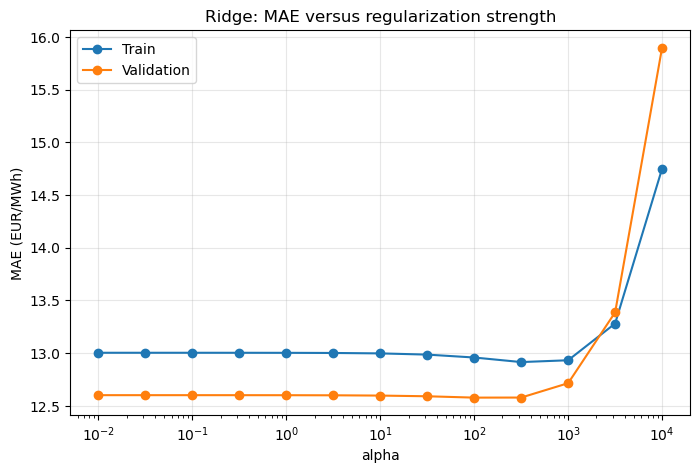

In [4]:
alphas = np.logspace(-2, 4, 13)
tuning = tune_alpha(train, val, alphas)
display(tuning.round(3))

plt.figure(figsize=(8, 5))
plt.semilogx(tuning["alpha"], tuning["train_MAE"], marker="o", label="Train")
plt.semilogx(tuning["alpha"], tuning["val_MAE"], marker="o", label="Validation")
plt.xlabel("alpha")
plt.ylabel("MAE (EUR/MWh)")
plt.title("Ridge: MAE versus regularization strength")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:
best_alpha = tuning.loc[tuning["val_MAE"].idxmin(), "alpha"]
print("Best alpha:", best_alpha)

ridge = build_ridge(best_alpha).fit(train[FEATURES], train[TARGET])

Best alpha: 100.0


## Comparison: baselines vs Ridge

In [6]:
pred_train = baseline_train[["daily_naive", "hybrid_naive"]].copy()
pred_train["ridge"] = ridge.predict(train[FEATURES])

pred_val = baseline_val[["daily_naive", "hybrid_naive"]].copy()
pred_val["ridge"] = ridge.predict(val[FEATURES])

comparison = pd.concat({
    "train": results_table(train[TARGET], pred_train),
    "validation": results_table(val[TARGET], pred_val),
})
comparison.round(3)

MAE    RMSE     R2   rMAE
           model                                     
train      daily_naive   12.125  28.203  0.893  1.000
           hybrid_naive  15.202  34.745  0.838  1.254
           ridge         12.958  25.616  0.912  1.069
validation daily_naive   13.029  26.185  0.397  1.000
           hybrid_naive  13.654  25.333  0.436  1.048
           ridge         12.578  22.835  0.542  0.965

### Actual vs predicted price: two weeks in winter and two weeks in summer (validation set)

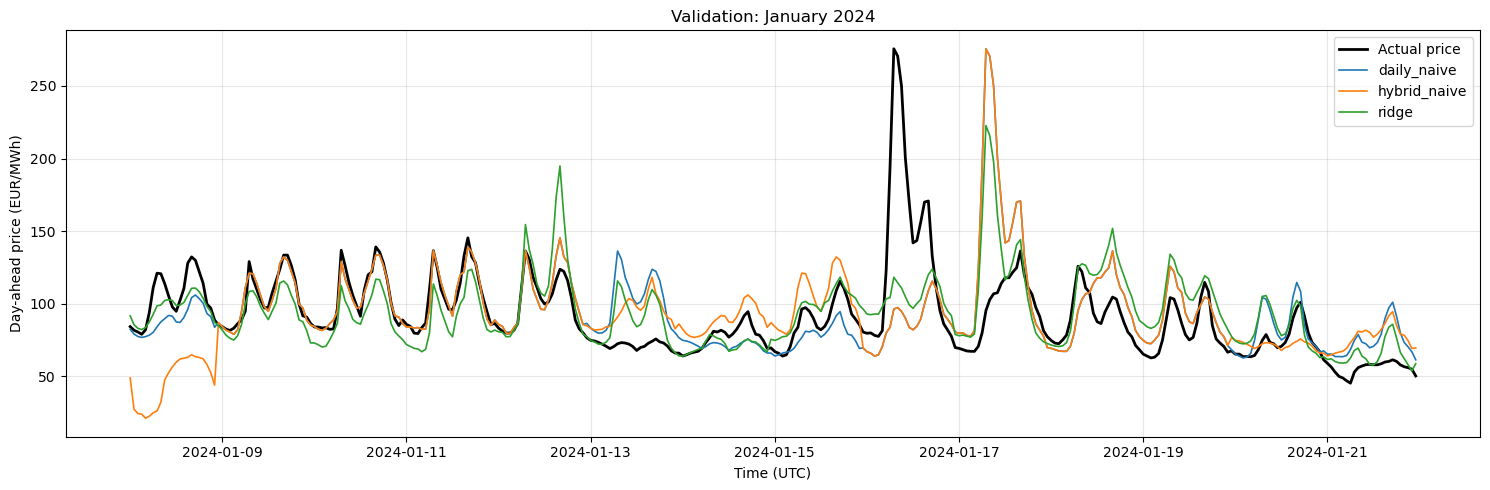

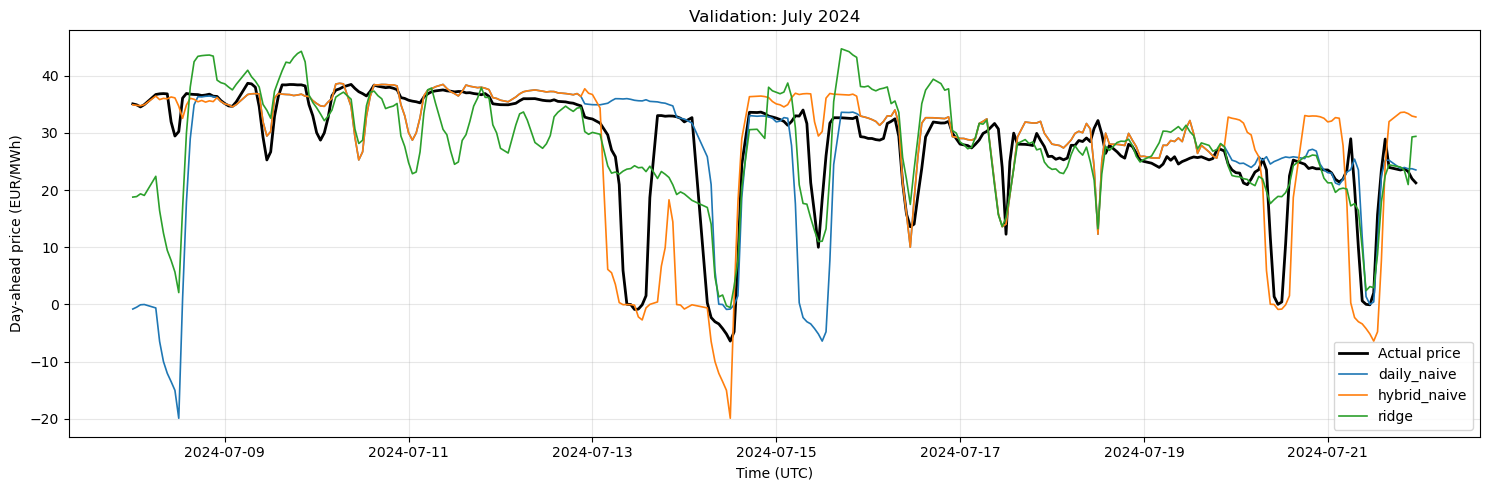

In [7]:
plot_time_series(val, pred_val, "2024-01-08", "2024-01-22", "Validation: January 2024")
plot_time_series(val, pred_val, "2024-07-08", "2024-07-22", "Validation: July 2024")

### Daily average price over the whole validation year

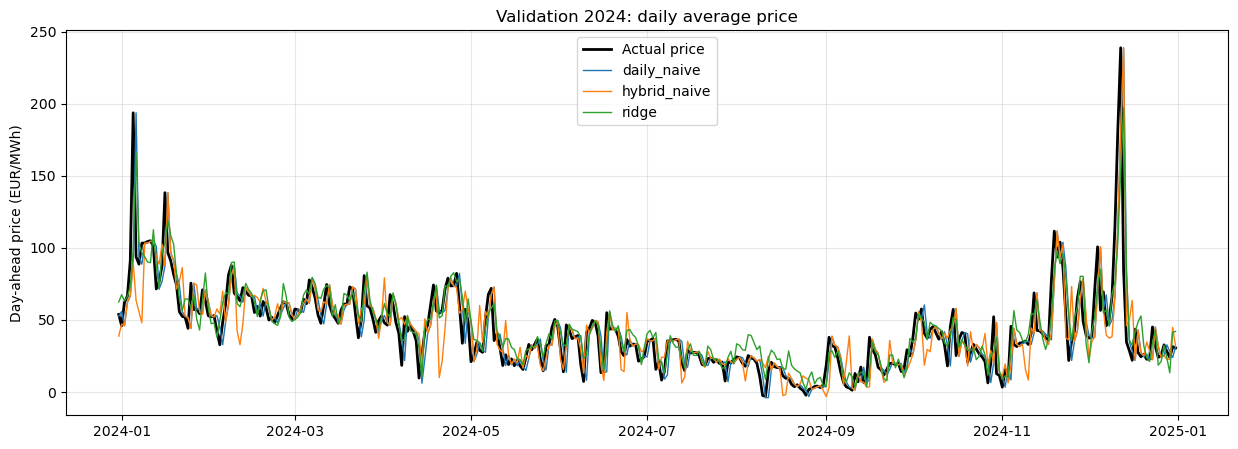

In [8]:
daily = pd.concat([val[["timestamp", TARGET]], pred_val], axis=1).set_index("timestamp").resample("D").mean()

plt.figure(figsize=(15, 5))
plt.plot(daily.index, daily[TARGET], color="black", linewidth=2, label="Actual price")
for model in pred_val.columns:
    plt.plot(daily.index, daily[model], linewidth=1, label=model)
plt.title("Validation 2024: daily average price")
plt.ylabel("Day-ahead price (EUR/MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Parity plots (validation set)

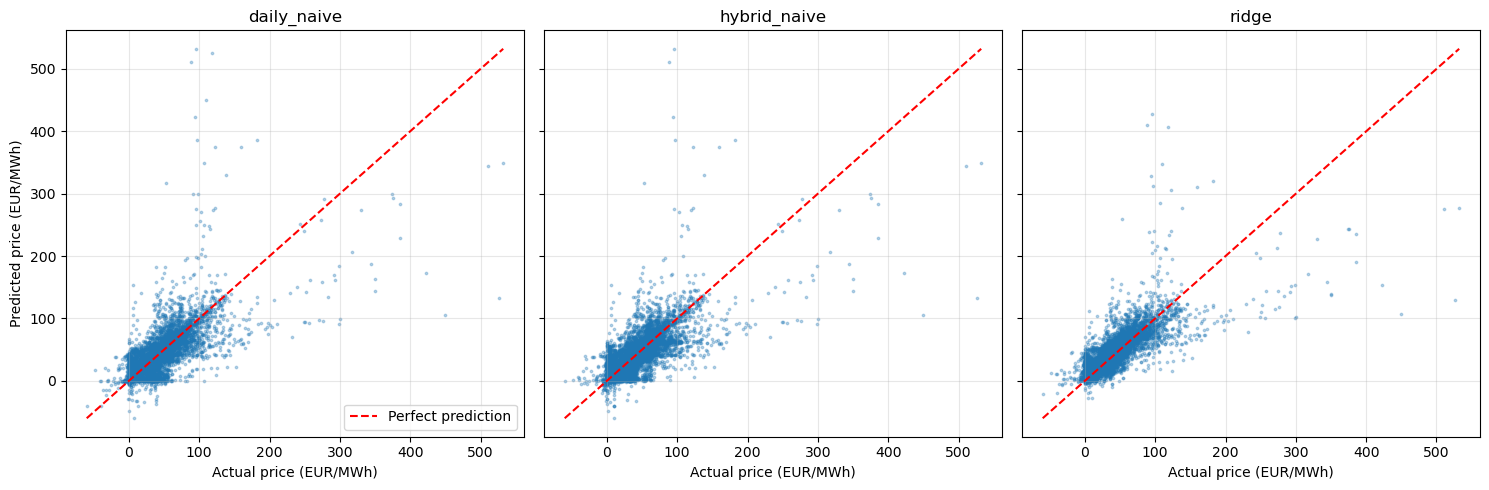

In [9]:
plot_parity(val[TARGET], pred_val)

### Residuals (validation set)

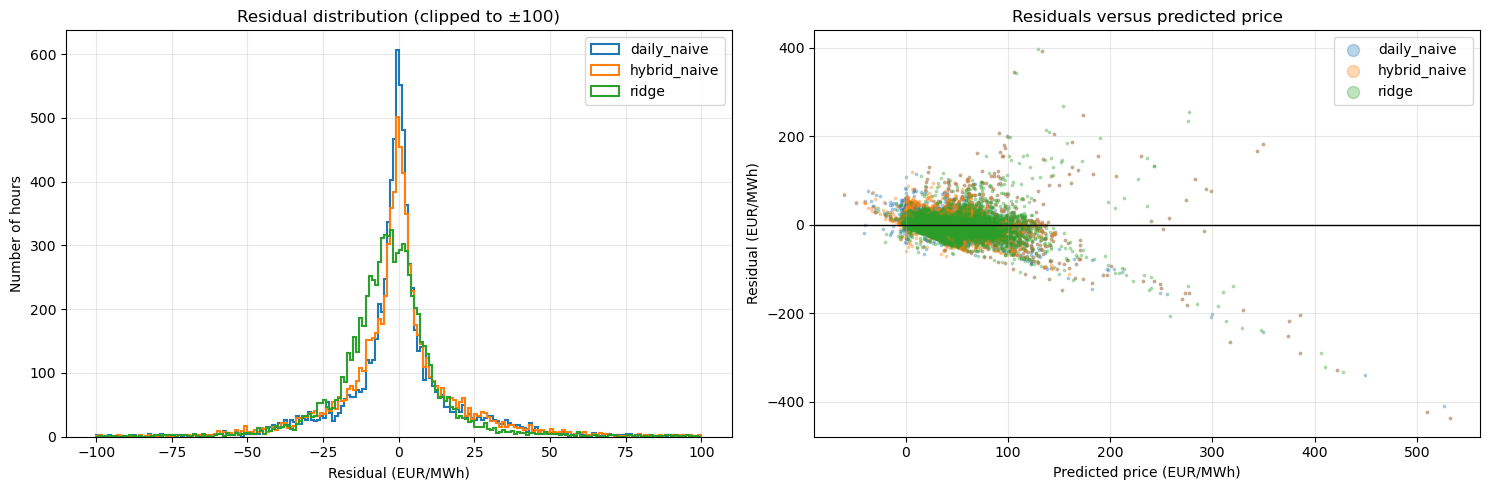

In [10]:
plot_residuals(val[TARGET], pred_val)

### When are the errors largest? (validation set)

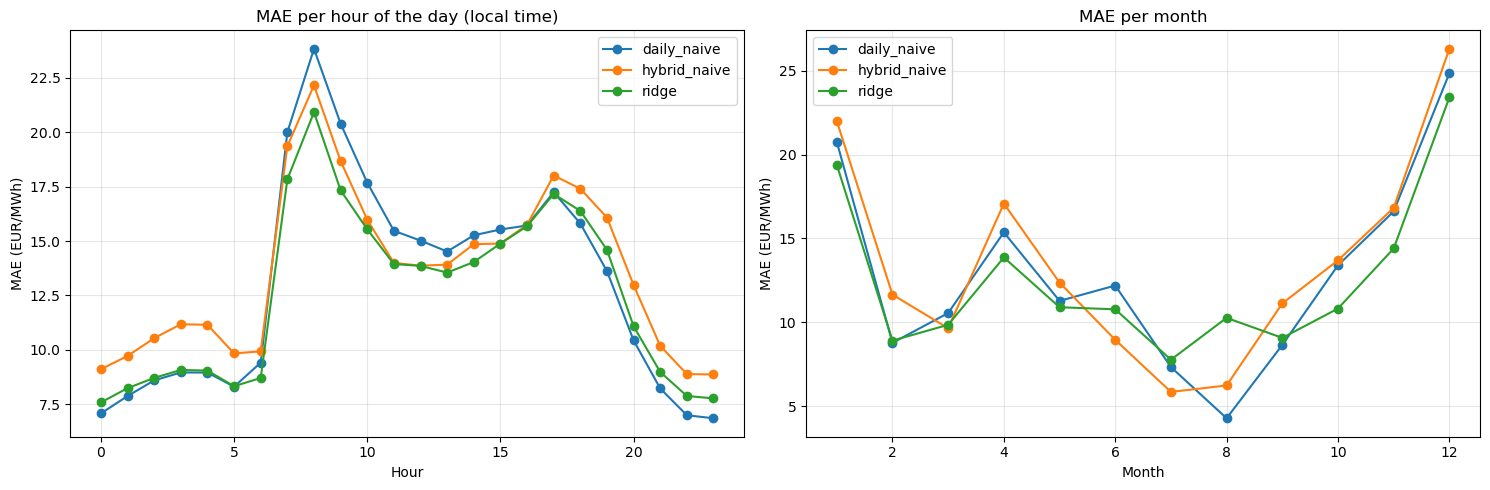

In [11]:
plot_error_by_group(val, pred_val)

### Ridge coefficients

The numeric features are standardized, so their coefficients are comparable: the change in price (EUR/MWh) for a one standard deviation change in the feature.
Calendar coefficients are the price difference relative to the first category (hour 0, Monday, January).

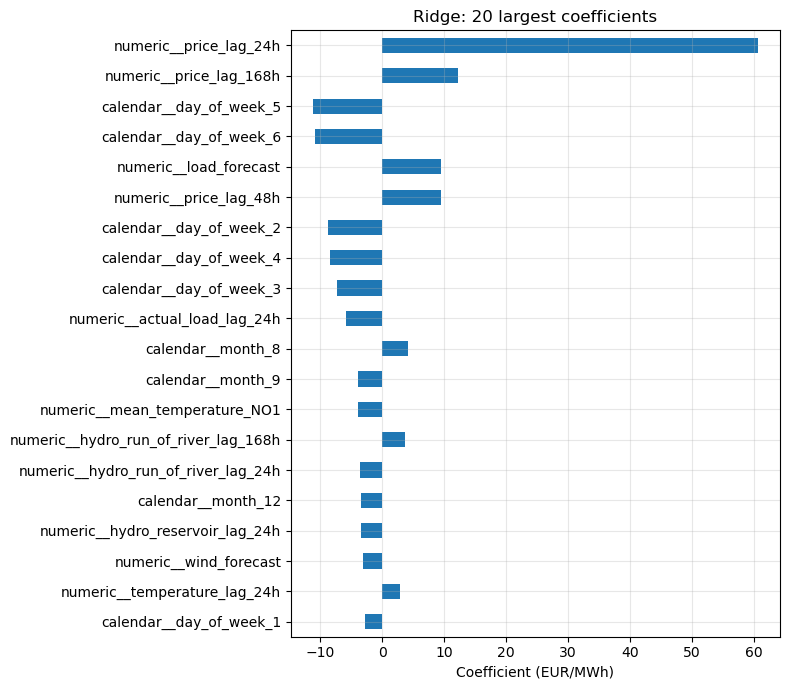

In [12]:
coefs = coefficients(ridge)

plt.figure(figsize=(8, 7))
coefs.head(20)[::-1].plot.barh()
plt.title("Ridge: 20 largest coefficients")
plt.xlabel("Coefficient (EUR/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()